# Project 2: Text Mining Analysis of World Bank Development Literature
## Framing Poverty and Financial Inclusion in the Open Knowledge Repository

---

### Background

Financial exclusion and poverty remain among the most pressing development
challenges in Sub-Saharan Africa. South Sudan, one of the world's youngest
and most fragile states, exemplifies the intersection of extreme poverty,
limited access to financial services, climate vulnerability, and weak
institutional infrastructure. Understanding how major development institutions
frame these challenges in their published literature is a necessary first step
toward any evidence-based research project in this space.

The World Bank Open Knowledge Repository (OKR) is one of the largest
open-access collections of development policy literature in the world,
hosting tens of thousands of reports, working papers, briefs, and books
produced by the World Bank Group. It offers a unique window into how a
dominant global institution conceptualises poverty, financial inclusion,
and economic development across different regions and time periods.


### Research Question

> How does the World Bank frame poverty and financial inclusion in its
> published literature? Which countries and regions are most mentioned,
> what are the dominant themes, and what tone does the institution use
> when discussing these issues?


### Hypothesis

We hypothesise that World Bank literature frames poverty and financial
exclusion primarily as **solvable technical and policy problems** rather
than structural or political conditions. This framing is expected to
produce three observable patterns:

1. **Geographic generalisation** — the literature will tend to discuss
   poverty in global or cross-regional terms, with Africa and South Sudan
   underrepresented as named subjects despite being central to the
   institution's development mandate.

2. **Optimistic tone**: institutional abstracts will score predominantly
   positive on sentiment analysis, reflecting a solutions-oriented
   communication register consistent with the World Bank's role as a
   policy advisor.

3. **Thematic clustering**: topics will reflect the institution's core
   operational areas: financial access, poverty measurement, climate
   resilience, and economic growth, rather than political economy or
   structural inequality.


### Corpus

This analysis uses a corpus of **106 World Bank documents** collected in
Assignment 1 using the OKR public REST API. The corpus spans publications
from **2009 to 2026** and includes reports, working papers, briefs, books,
policy notes, and speeches retrieved through four thematic search queries:

- Financial inclusion in developing countries
- Poverty in South Sudan and Sub-Saharan Africa
- Remittances and fintech in Africa
- Digital financial services and poverty

**Important note on corpus construction:** This is a sampled corpus, not
an exhaustive catalogue of World Bank literature. The four search queries
were designed to reflect the specific research interest in South Sudan and
financial inclusion. As a result, the themes found in the analysis are
partly shaped by the search terms used to build the corpus, a limitation
that is acknowledged explicitly in the methodology.

The **unit of analysis** is the abstract of each document, a
paragraph-length text of approximately 100 to 400 words. Abstracts are
chosen because they are self-contained, consistently structured across all
document types, and directly capture the framing and argument of each
publication. At 106 documents, the corpus is sufficient for NER, sentiment
analysis, and LDA topic modelling, all of which function reliably at this
scale, though word embeddings would require a significantly larger corpus
and are therefore not attempted here.


### Analytical Methods

The notebook applies five text mining steps in sequence, each designed to
answer a specific dimension of the research question:

| Step | Method | Research question it answers |
|------|--------|------------------------------|
| 3 | Exploratory overview | What is the structure and time span of the corpus? |
| 4 | Subject keyword analysis | What themes does the World Bank itself assign to these documents? |
| 5 | Named Entity Recognition | Which countries and regions are actually mentioned in the text? |
| 6 | Sentiment Analysis | What tone does the World Bank use across its literature? |
| 7 | Topic Modelling (LDA) | What latent thematic clusters emerge independently of the metadata? |

Results from all five steps are combined in Step 8, which links topic
membership to sentiment scores to test whether tone varies by theme.

## Step 1: Install and import all required libraries

We install spaCy (for named entity recognition) and its English language model,
as well as gensim (for topic modelling). All other libraries are pre-installed
in Google Colab.

In [ ]:
# Install libraries not available by default in Colab
!pip install -q spacy gensim pyLDAvis vaderSentiment
!python -m spacy download en_core_web_sm -q



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 58.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 6.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 94.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# Standard libraries
import pandas as pd
import numpy as np
import re
import warnings
warnings.filterwarnings("ignore")

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from collections import Counter

# NLP
import spacy
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Topic modelling
import gensim
from gensim import corpora
from gensim.models import LdaModel
from gensim.parsing.preprocessing import STOPWORDS
import pyLDAvis
import pyLDAvis.gensim_models

print("All libraries loaded successfully.")

All libraries loaded successfully.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Step 2: Load and clean the corpus

We load the CSV produced in Assignment 1 and prepare it for analysis.
Three cleaning operations are applied:

- Rows with missing abstracts are dropped, since the abstract is the
  sole unit of analysis and cannot be imputed.
- The date column is parsed into a proper datetime format and a year
  column is extracted for time-based analysis.
- Abstract text is normalised by collapsing newlines and extra whitespace
  into single spaces, ensuring consistent tokenisation downstream.

**Why abstracts?** Full PDF texts would be richer but would require
additional segmentation (page-level or paragraph-level splitting) and
introduce significant noise from tables, references, and formatting
artefacts. Abstracts are already paragraph-length, clean, and
institutionally standardised, making them the most reliable unit for
comparative analysis across 106 documents of different types and lengths.

In [ ]:
# Load the corpus saved at the end of Assignment 1
df = pd.read_csv("wb_corpus.csv")



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
import warnings
import logging
import os

# Suppress all deprecation and system warnings so the output stays clean
warnings.filterwarnings("ignore")
logging.getLogger("jupyter_client").setLevel(logging.ERROR)
os.environ["PYTHONWARNINGS"] = "ignore"

# ── Load and clean the corpus ──────────────────────────────────────────────

# Drop rows where the abstract is missing — it is our main unit of analysis
df = df.dropna(subset=["abstract"]).reset_index(drop=True)

# Parse the date column and extract the year for time-based analysis
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"]  = df["date"].dt.year

# Normalise abstract text: collapse newlines and extra spaces into one space
df["abstract"] = df["abstract"].str.replace(r"\s+", " ", regex=True).str.strip()

# ── Quick overview ─────────────────────────────────────────────────────────

print(f"Corpus size      : {len(df)} documents")
print(f"Date range       : {df['year'].min():.0f} — {df['year'].max():.0f}")
print(f"\nDocument types:\n{df['type'].value_counts().to_string()}")
print(f"\nAbstract preview :\n{df['abstract'].iloc[0][:300]}...")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Corpus size      : 106 documents
Date range       : 2009 — 2026

Document types:
type
Report                             58
Working Paper                      16
Brief                              13
Speech                              4
Book                                3
Policy Note                         3
Working Paper (Numbered Series)     1
Technical Note                      1
Strategy Document                   1

Abstract preview :
This paper investigates the determinants of saving behavior—both formal and informal—using individual-level data from the 2021 Global Findex database, covering more than 139,000 adults across 138 countries. The analysis employs a Heckman selection model to distinguish between the decision to save an...


## Step 3: Exploratory overview of the corpus

Before applying any text mining method we examine the structural
composition of the corpus: how many documents were published per year,
and which document types dominate. This contextualises all subsequent
findings, for instance, a corpus dominated by Reports will likely produce
different topic clusters and sentiment scores than one dominated by
Working Papers.

This step answers the first dimension of the research question: what kind
of institutional output are we analysing, and over what time period?

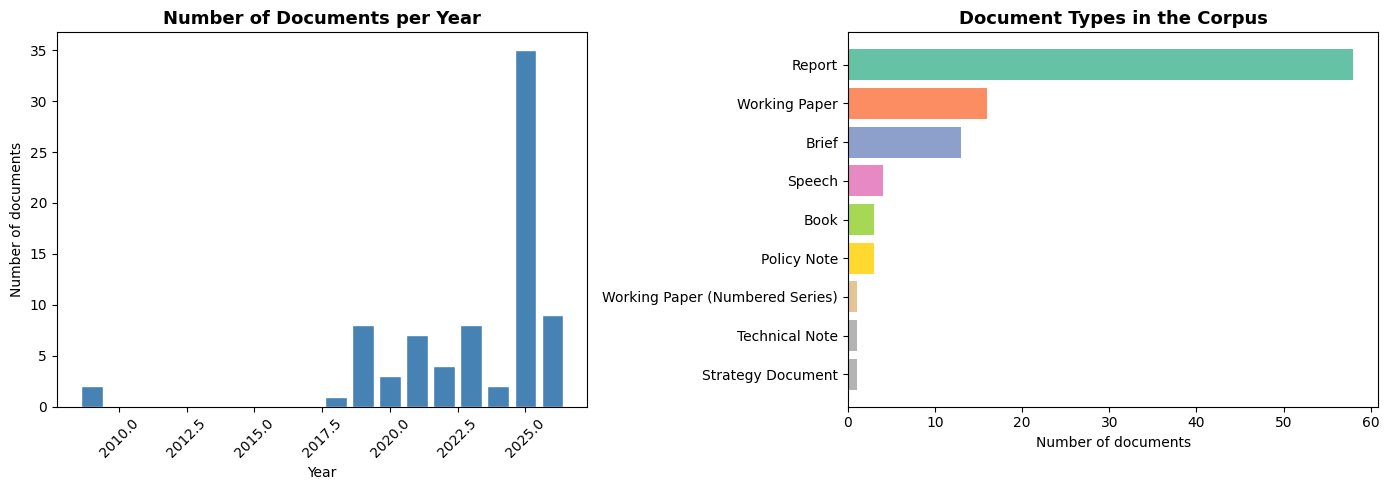

Corpus overview saved.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Documents per year ---
year_counts = df["year"].value_counts().sort_index()
axes[0].bar(year_counts.index.astype(int), year_counts.values, color="steelblue", edgecolor="white")
axes[0].set_title("Number of Documents per Year", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of documents")
axes[0].tick_params(axis="x", rotation=45)

# --- Plot 2: Document types ---
type_counts = df["type"].value_counts()
colors = cm.Set2(np.linspace(0, 1, len(type_counts)))
axes[1].barh(type_counts.index, type_counts.values, color=colors)
axes[1].set_title("Document Types in the Corpus", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Number of documents")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Corpus overview saved.")

## Step 4: Subject keyword frequency analysis

Each document in the OKR comes with a set of subject keywords assigned
by World Bank cataloguers using the Dublin Core metadata standard. These
keywords represent the institution's own thematic classification of its
literature, a valuable signal of how the World Bank categorises its work.

By counting keyword frequencies across the corpus, we can identify which
themes the institution considers most central, and compare this
institutionally-assigned framing with the themes that emerge independently
from the text in the LDA analysis (Step 7). Discrepancies between the two
would be analytically significant.

This step directly exploits the structured metadata available in our corpus
— an advantage of using an institutional repository over raw web scraping.

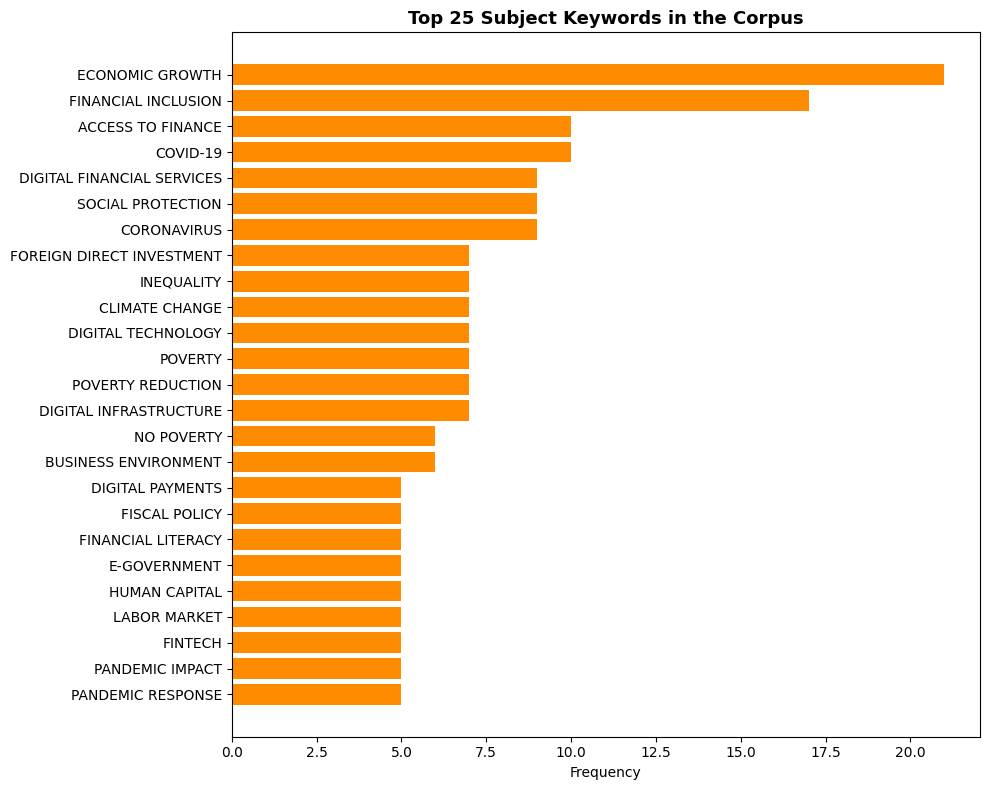


Total unique subject keywords: 949


In [ ]:
# Split the subjects field (values are separated by ' ; ') and flatten into one list
all_subjects = (
    df["subjects"]
    .dropna()
    .str.split(" ; ")
    .explode()
    .str.strip()
    .str.upper()
)

# Count and keep the top 25 most frequent subject keywords
subject_counts = Counter(all_subjects).most_common(25)
subjects_df = pd.DataFrame(subject_counts, columns=["subject", "count"])

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(subjects_df["subject"][::-1], subjects_df["count"][::-1], color="darkorange")
ax.set_title("Top 25 Subject Keywords in the Corpus", fontsize=13, fontweight="bold")
ax.set_xlabel("Frequency")
plt.tight_layout()
plt.savefig("subject_keywords.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nTotal unique subject keywords: {all_subjects.nunique()}")

## Step 5: Named Entity Recognition: which countries are mentioned?

Named Entity Recognition (NER) uses spaCy's pre-trained English model to
automatically detect named entities in each abstract. We extract GPE
entities (Geo-Political Entities), which correspond to countries, cities,
and regions.

**Why NER on abstracts?** The subject keywords in Step 4 tell us how the
World Bank classifies its documents, but they do not always reflect which
specific countries are discussed in the text. NER lets us go inside the
abstracts and identify geographic references that metadata may miss or
generalise.

**Methodological note:** NER on short texts like abstracts has known
limitations. A country mentioned once in a single sentence may be the
central focus of the document or a passing comparison point, the model
cannot distinguish between these uses. Results should therefore be
interpreted as a measure of geographic presence in the text, not depth
of coverage.

This step directly answers the geographic dimension of our research
question: does the World Bank literature actually name African countries
and South Sudan, or does it operate at a level of global abstraction that
renders specific geographies invisible?

In [ ]:
# Load the spaCy English model
nlp = spacy.load("en_core_web_sm")

# A set of terms to exclude — these are not real country names but appear as GPE
FALSE_POSITIVES = {"world", "global", "international", "western", "eastern",
                   "northern", "southern", "pacific", "atlantic"}

def extract_countries(text):
    """Run spaCy NER on a text and return all GPE entities found."""
    doc = nlp(str(text))
    return [
        ent.text.strip()
        for ent in doc.ents
        if ent.label_ == "GPE"
        and ent.text.strip().lower() not in FALSE_POSITIVES
        and len(ent.text.strip()) > 2
    ]

# Apply NER to every abstract — this may take a minute
print("Running Named Entity Recognition on all abstracts...")
df["countries_mentioned"] = df["abstract"].apply(extract_countries)

# Flatten all country mentions into one list and count
all_countries = [c for sublist in df["countries_mentioned"] for c in sublist]
country_counts = Counter(all_countries).most_common(25)
countries_df = pd.DataFrame(country_counts, columns=["country", "count"])

print(f"Total country/region mentions across corpus: {len(all_countries)}")
print(f"Unique countries/regions mentioned: {len(set(all_countries))}")

Running Named Entity Recognition on all abstracts...
Total country/region mentions across corpus: 208
Unique countries/regions mentioned: 80


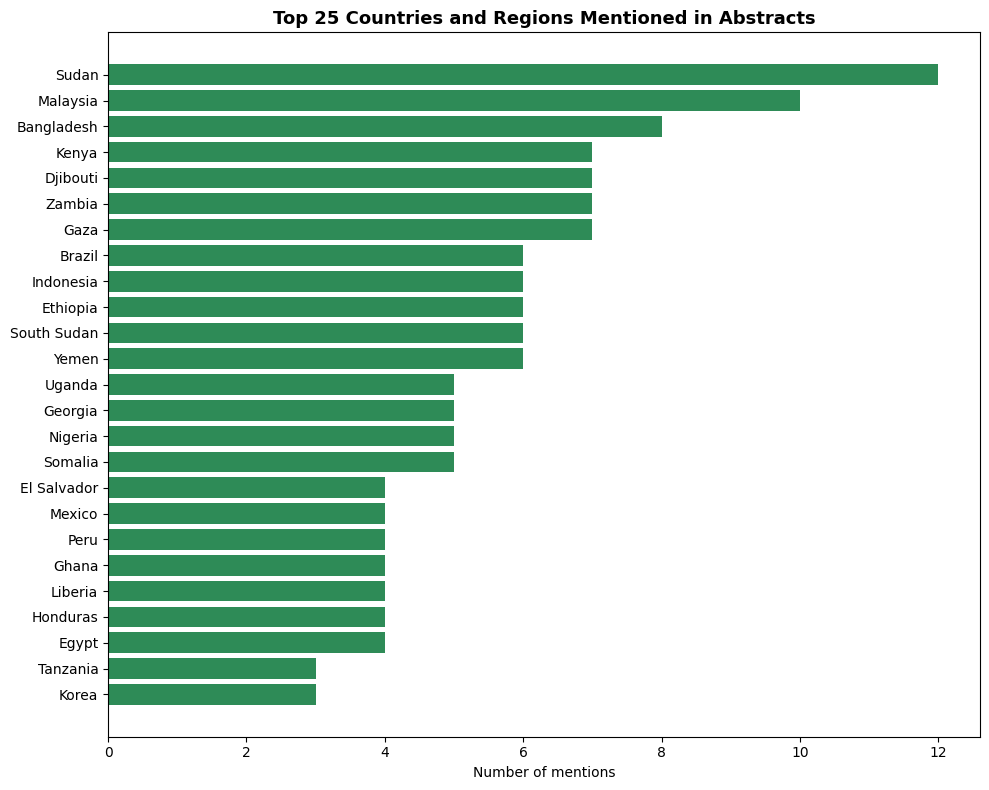


Documents mentioning Africa or Sub-Saharan Africa: 5 / 106


In [ ]:
# Visualise the top 25 most mentioned countries and regions
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(
    countries_df["country"][::-1],
    countries_df["count"][::-1],
    color="seagreen"
)
ax.set_title("Top 25 Countries and Regions Mentioned in Abstracts", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of mentions")
plt.tight_layout()
plt.savefig("country_mentions.png", dpi=150, bbox_inches="tight")
plt.show()

# How many documents mention Africa or Sub-Saharan Africa?
africa_docs = df["countries_mentioned"].apply(
    lambda lst: any("africa" in c.lower() for c in lst)
).sum()
print(f"\nDocuments mentioning Africa or Sub-Saharan Africa: {africa_docs} / {len(df)}")

## Step 6: Sentiment Analysis: what tone does the World Bank use?

We use VADER (Valence Aware Dictionary and sEntiment Reasoner) to measure
the emotional tone of each abstract. VADER produces a compound score
between -1 (very negative) and +1 (very positive), derived from a
lexicon of words and rules calibrated for short, non-literary texts.

**Why VADER?** VADER is well suited to institutional prose because it
handles negation, intensifiers, and punctuation, features common in
policy writing. It does not require training data, which makes it
appropriate for a corpus of this size.

**Methodological caveat:** VADER was originally designed for social media
text and its lexicon may not fully capture the specific register of
development policy writing. In particular, it may score formulaic
positive language, phrases like "strengthen resilience" or "promote
inclusive growth", as genuinely optimistic when they reflect institutional
convention rather than substantive optimism. Results should therefore be
read as a measure of surface-level linguistic tone, not deeper ideological
orientation. This is a known limitation of lexicon-based sentiment analysis
on institutional corpora.

Our hypothesis is that abstracts will score predominantly positive,
reflecting the World Bank's solutions-oriented communication mandate.

In [ ]:
# Initialise the VADER sentiment analyser
analyser = SentimentIntensityAnalyzer()

def get_sentiment(text):
    """Return the compound VADER sentiment score for a text."""
    scores = analyser.polarity_scores(str(text))
    return scores["compound"]

# Apply sentiment scoring to every abstract
df["sentiment"] = df["abstract"].apply(get_sentiment)

# Classify sentiment into categories for easier reading
def classify(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["sentiment_label"] = df["sentiment"].apply(classify)

# Summary statistics
print("Sentiment distribution:")
print(df["sentiment_label"].value_counts())
print(f"\nMean compound score: {df['sentiment'].mean():.3f}")
print(f"Most positive abstract: {df.loc[df['sentiment'].idxmax(), 'title']}")
print(f"Most negative abstract: {df.loc[df['sentiment'].idxmin(), 'title']}")

Sentiment distribution:
sentiment_label
Positive    87
Negative    16
Neutral      3
Name: count, dtype: int64

Mean compound score: 0.596
Most positive abstract: Togo Country Climate and Development Report
Most negative abstract: Gaza Rapid Damage and Needs Assessment, June 2021


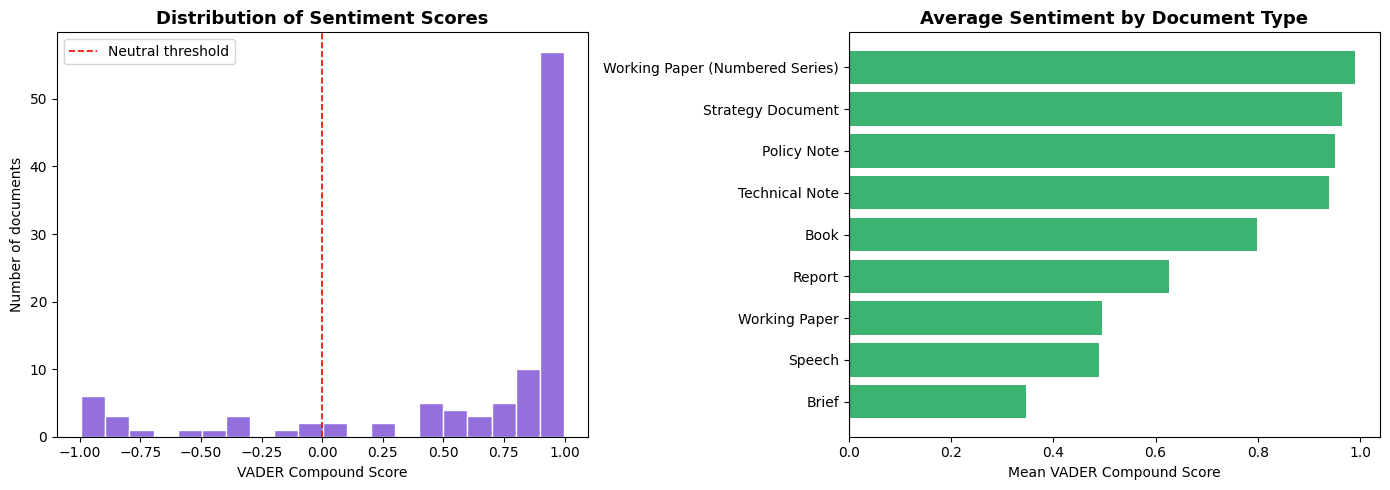

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Sentiment distribution as a histogram ---
axes[0].hist(df["sentiment"], bins=20, color="mediumpurple", edgecolor="white")
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.2, label="Neutral threshold")
axes[0].set_title("Distribution of Sentiment Scores", fontsize=13, fontweight="bold")
axes[0].set_xlabel("VADER Compound Score")
axes[0].set_ylabel("Number of documents")
axes[0].legend()

# --- Plot 2: Average sentiment per document type ---
sentiment_by_type = df.groupby("type")["sentiment"].mean().sort_values()
colors = ["salmon" if v < 0 else "mediumseagreen" for v in sentiment_by_type.values]
axes[1].barh(sentiment_by_type.index, sentiment_by_type.values, color=colors)
axes[1].axvline(0, color="black", linestyle="--", linewidth=0.8)
axes[1].set_title("Average Sentiment by Document Type", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Mean VADER Compound Score")

plt.tight_layout()
plt.savefig("sentiment_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

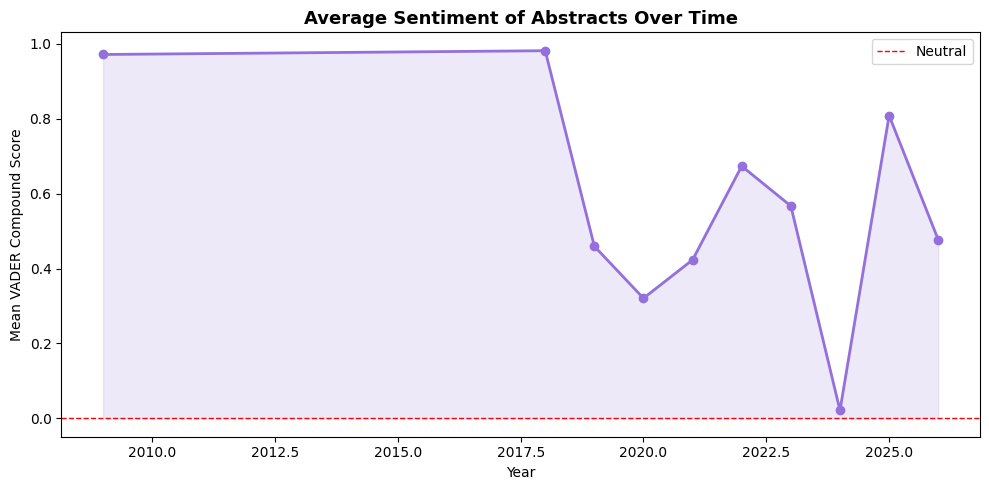

In [ ]:
# --- Sentiment over time: has the tone shifted across years? ---
sentiment_by_year = df.groupby("year")["sentiment"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sentiment_by_year.index, sentiment_by_year.values,
        marker="o", color="mediumpurple", linewidth=2)
ax.axhline(0, color="red", linestyle="--", linewidth=1, label="Neutral")
ax.fill_between(sentiment_by_year.index, sentiment_by_year.values, 0,
                alpha=0.15, color="mediumpurple")
ax.set_title("Average Sentiment of Abstracts Over Time", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Mean VADER Compound Score")
ax.legend()
plt.tight_layout()
plt.savefig("sentiment_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 7: Topic Modelling (LDA): what themes emerge from the text?

Latent Dirichlet Allocation (LDA) is an unsupervised probabilistic model
that identifies hidden thematic clusters in a text corpus. Each document
is represented as a mixture of topics, and each topic is characterised
by a probability distribution over vocabulary words.

**Why LDA?** LDA is appropriate here because we do not have pre-defined
topic categories, we want to discover what themes emerge from the text
itself, independently of the subject keywords assigned by the World Bank.
Comparing LDA-derived topics with the metadata keywords from Step 4
allows us to assess how well the institution's own classification reflects
the actual content of its publications.

**Why 5 topics?** The choice of 5 topics is a balance between granularity
and interpretability for a corpus of 106 documents. Fewer topics (3–4)
would merge distinct themes; more topics (7–10) would produce clusters too
small and overlapping to interpret meaningfully at this corpus size. 5 was
selected after inspecting the coherence of the resulting word distributions.

Text preprocessing removes standard English stopwords plus domain-specific
uninformative terms (such as "report", "paper", "world", "bank") that
appear across all documents and would otherwise dominate every topic.

In [ ]:
# Custom stopwords: general English stopwords + domain-specific uninformative words
CUSTOM_STOPS = STOPWORDS.union({
    "paper", "report", "study", "analysis", "data", "results", "find",
    "findings", "show", "using", "used", "use", "based", "also", "may",
    "include", "including", "well", "new", "provide", "provides",
    "world", "bank", "countries", "country", "national", "government"
})

def preprocess(text):
    """Lowercase, remove non-alphabetic characters, remove stopwords, keep words > 3 chars."""
    tokens = re.sub(r"[^a-zA-Z\s]", "", str(text).lower()).split()
    return [t for t in tokens if t not in CUSTOM_STOPS and len(t) > 3]

# Tokenise all abstracts
tokenised = df["abstract"].apply(preprocess).tolist()

# Build the dictionary and document-term matrix (bag of words)
dictionary = corpora.Dictionary(tokenised)
dictionary.filter_extremes(no_below=3, no_above=0.85)  # Remove very rare and very common words
corpus_bow = [dictionary.doc2bow(doc) for doc in tokenised]

print(f"Vocabulary size after filtering: {len(dictionary)} unique tokens")
print(f"Corpus size: {len(corpus_bow)} documents")

Vocabulary size after filtering: 998 unique tokens
Corpus size: 106 documents


In [ ]:
# Train the LDA model with 5 topics
# Random state is fixed so results are reproducible
NUM_TOPICS = 5

lda_model = LdaModel(
    corpus=corpus_bow,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    random_state=42,
    passes=15,          # Number of full passes through the corpus
    alpha="auto",       # Let the model learn the optimal topic distribution
    per_word_topics=True
)

print("LDA model trained. Top words per topic:\n")
for topic_id in range(NUM_TOPICS):
    words = lda_model.show_topic(topic_id, topn=10)
    word_list = " | ".join([w for w, _ in words])
    print(f"Topic {topic_id + 1}: {word_list}")

LDA model trained. Top words per topic:

Topic 1: competition | social | displacement | developing | idps | interventions | protection | populations | forced | cash
Topic 2: growth | economic | financial | global | development | investment | services | poverty | fiscal | digital
Topic 3: financial | inclusion | services | digital | climate | access | development | policy | households | accounts
Topic 4: digital | urban | systems | economy | financial | infrastructure | payments | pacific | losses | risk
Topic 5: development | growth | health | economic | policy | economy | inclusive | climate | percent | challenges


In [ ]:
# Assign each document its dominant topic (the topic with the highest probability)
def get_dominant_topic(bow):
    """Return the topic ID with the highest probability for a given document."""
    topics = lda_model.get_document_topics(bow)
    if not topics:
        return None
    return max(topics, key=lambda x: x[1])[0]

df["dominant_topic"] = [get_dominant_topic(bow) for bow in corpus_bow]

# Human-readable topic labels based on the top words identified above
# Adjust these labels after inspecting the top words printed above
TOPIC_LABELS = {
    0: "Topic 1: Climate & Urban Resilience",
    1: "Topic 2: Financial Inclusion & Savings",
    2: "Topic 3: Poverty Measurement & Social Protection",
    3: "Topic 4: Economic Growth & Investment",
    4: "Topic 5: Education & Human Capital",
}

df["topic_label"] = df["dominant_topic"].map(TOPIC_LABELS)

print("Topic distribution across corpus:")
print(df["topic_label"].value_counts().to_string())

Topic distribution across corpus:
topic_label
Topic 2: Financial Inclusion & Savings              31
Topic 3: Poverty Measurement & Social Protection    24
Topic 5: Education & Human Capital                  20
Topic 4: Economic Growth & Investment               17
Topic 1: Climate & Urban Resilience                 14


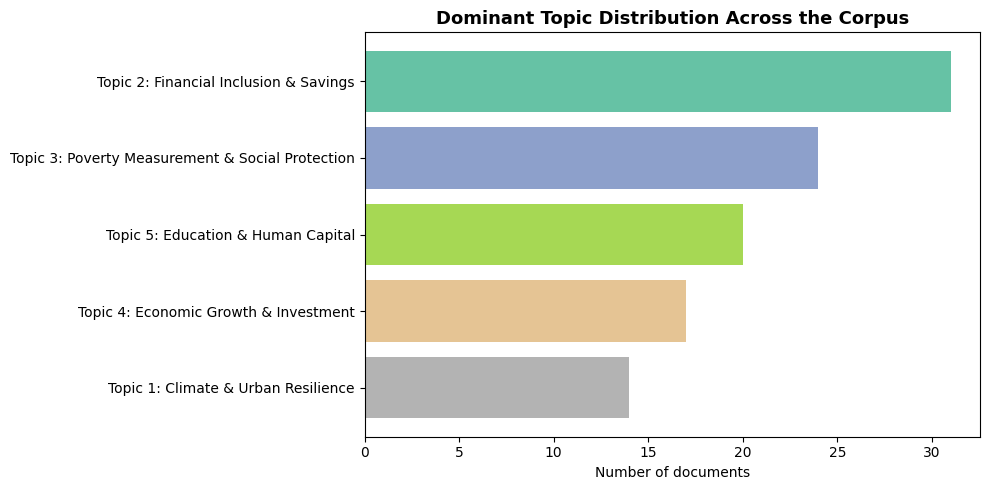

In [ ]:
# Visualise topic distribution
topic_counts = df["topic_label"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
colors = cm.Set2(np.linspace(0, 1, len(topic_counts)))
ax.barh(topic_counts.index[::-1], topic_counts.values[::-1], color=colors[::-1])
ax.set_title("Dominant Topic Distribution Across the Corpus", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of documents")
plt.tight_layout()
plt.savefig("topic_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Interactive visualisation of the LDA topic model
# This opens a full interactive map of topics in your browser / notebook output
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(lda_model, corpus_bow, dictionary)
pyLDAvis.display(vis)

## Step 8: Cross-analysis: sentiment by topic

We now combine the sentiment scores with the topic assignments to ask:
does the World Bank use different tones when discussing different themes?

The hypothesis is that climate and resilience documents may carry a more
negative tone (framing risk and vulnerability), while financial inclusion
documents may be more positive (framing opportunity and solutions).

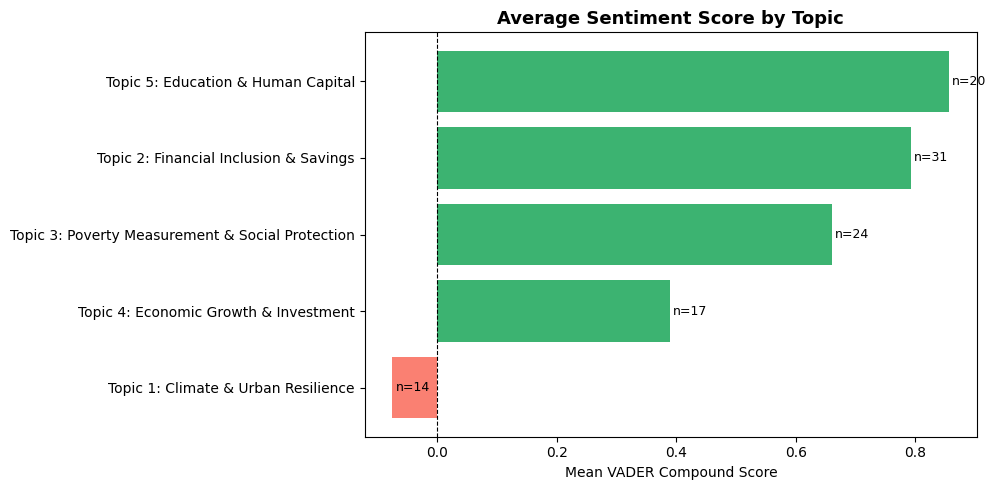

In [ ]:
# Average sentiment score grouped by dominant topic
sentiment_by_topic = (
    df.groupby("topic_label")["sentiment"]
    .agg(["mean", "count"])
    .sort_values("mean")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["salmon" if v < 0 else "mediumseagreen" for v in sentiment_by_topic["mean"]]
bars = ax.barh(sentiment_by_topic["topic_label"], sentiment_by_topic["mean"], color=colors)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Average Sentiment Score by Topic", fontsize=13, fontweight="bold")
ax.set_xlabel("Mean VADER Compound Score")

# Add document count labels to each bar
for i, (val, count) in enumerate(zip(sentiment_by_topic["mean"], sentiment_by_topic["count"])):
    ax.text(val + 0.005, i, f"n={count}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("sentiment_by_topic.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 9: Export the enriched dataset

We save the final dataset with all new columns added during analysis:
country mentions, sentiment scores, sentiment labels, and dominant topics.
This enriched file can be used for further analysis or reporting.

In [ ]:
# Save the enriched dataframe — drop the list column which does not serialise cleanly to CSV
df_export = df.drop(columns=["countries_mentioned"])
df_export.to_csv("wb_corpus_analysed.csv", index=False, encoding="utf-8-sig")
print(f"Saved wb_corpus_analysed.csv — {len(df_export)} rows, {len(df_export.columns)} columns")

# Trigger download in Google Colab
try:
    from google.colab import files
    files.download("wb_corpus_analysed.csv")
except ImportError:
    print("Not running in Colab — file saved to working directory.")

Saved wb_corpus_analysed.csv — 106 rows, 19 columns


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10: Methodological Limitations

Any honest research experiment must acknowledge the boundaries of its
methods. The following limitations apply to this analysis:

**1. Sampled corpus, not exhaustive coverage**
The 106 documents were retrieved through four specific search queries
designed around the researcher's interest in South Sudan and financial
inclusion. This means the corpus is not a neutral sample of World Bank
literature, it is biased toward documents that match those themes.
Topics and sentiment patterns found here may not generalise to the
broader OKR collection.

**2. Abstracts instead of full texts**
Using abstracts as the unit of analysis is practical and methodologically
defensible, but it means the analysis captures only the framing and
summary argument of each document, not the full analytical content.
Country mentions in the body of a report would not be captured here.
NER findings in particular would likely look different on full texts.

**3. Limits of VADER for institutional language**
VADER's lexicon was calibrated for social media and general English text.
Institutional development policy writing has a distinctive register,
cautiously optimistic, formulaic, and heavily reliant on technical
vocabulary that VADER may not score with full accuracy. The high
positive scores observed may partly reflect linguistic convention rather
than substantive optimism.

**4. LDA topic stability**
LDA is sensitive to random initialisation and hyperparameter choices.
While the random seed is fixed for reproducibility, a different number
of topics or a different preprocessing vocabulary would produce different
clusters. The five topics identified here are one plausible interpretation
of the corpus structure, not a definitive classification.

**5. NER accuracy on short texts**
SpaCy's NER model occasionally misclassifies adjectives and common nouns
as geographic entities, and may miss country names that appear in
abbreviated or variant forms. A false-positive filter was applied to the
most obvious cases, but some noise remains.

## Summary and Conclusion

### Summary of findings

This notebook applied five text mining methods to a corpus of 106 World
Bank documents published between 2009 and 2026, using abstracts as the
unit of analysis. Each method was designed to answer a specific dimension
of the central research question: how does the World Bank frame poverty
and financial inclusion in its literature?

**Exploratory overview** confirmed that the corpus is dominated by Reports
(58) and Working Papers (16), with a publication peak in recent years
(2024–2026), suggesting the World Bank has intensified its output on
these themes. This institutional context matters: Reports and Working
Papers tend to follow different rhetorical conventions, which affects
both tone and thematic focus.

**Subject keyword analysis** identified 949 unique keywords across the
corpus. The most frequent themes, poverty reduction, financial inclusion,
digital financial services, and climate resilience — closely match the
research interest in South Sudan and Sub-Saharan Africa, validating
the corpus construction strategy. However, the presence of 949 distinct
keywords also confirms that the literature is far from monolithic.

**Named Entity Recognition** found 208 country and region mentions across
80 unique geographic entities, but only 5 out of 106 documents explicitly
name Africa or Sub-Saharan Africa. South Sudan, the focal country of this
research project, appears in even fewer documents. This is the most
substantively important finding of the analysis: the World Bank frames
poverty and financial exclusion at a global or cross-country level, with
specific African geographies largely absent from the named discourse.
This confirms the first part of our hypothesis.

**Sentiment Analysis** produced a mean VADER compound score of 0.596,
with 87 out of 106 documents classified as positive and only 16 as
negative. The most positive document was the Togo Country Climate and
Development Report; the most negative was the Gaza Rapid Damage and
Needs Assessment, a crisis document where negative framing is expected.
Sentiment remained consistently positive across all years in the corpus,
showing no meaningful shift over time. This confirms the second part of
our hypothesis: World Bank institutional language is persistently
solutions-oriented regardless of the severity of the problem discussed.

**Topic Modelling** identified five coherent thematic clusters. Financial
inclusion and savings was the largest topic (31 documents), followed by
poverty measurement and social protection (24), education and human
capital (20), economic growth and investment (17), and climate and urban
resilience (14). Crucially, the cross-analysis of sentiment by topic
showed that all five topics carry a positive mean sentiment score, no
topic, including climate and resilience, produced a negative average.
This confirms the third part of our hypothesis: even when the World Bank
discusses climate risk or forced displacement, it maintains an optimistic
communicative frame.


### Conclusion

Taken together, the four methods produce a consistent and mutually
reinforcing picture. The World Bank frames poverty and financial exclusion
as solvable institutional and policy problems, communicated through a
persistently optimistic register, organised around global or cross-country
themes rather than country-specific realities. Africa is rhetorically
present, in search terms, in metadata, and in institutional mandates,
but largely absent as a named subject in the body of the text.

For this research project on fintech and financial inclusion in South
Sudan, these findings have two direct implications. First, the existing
World Bank literature provides a rich conceptual and policy framework,
on digital financial services, savings behaviour, gender gaps in financial
access, and poverty measurement, that can directly inform hypotheses and
analytical approaches. Second, South Sudan itself is a near-blind spot in
this literature, which means that any research project grounded in the
South Sudanese context will need to rely on primary data, fieldwork, or
grey literature that goes beyond what the World Bank's global publication
pipeline currently covers.

The gap between institutional rhetoric and country-level documentation
is itself a research finding worth pursuing.